In [ ]:

!pip install -q ultralytics fastapi uvicorn python-multipart opencv-python-headless nest-asyncio


In [ ]:

import cv2
import numpy as np
import torch
import time
import io
import os

from ultralytics import YOLO
from google.colab import files
from IPython.display import display, Image

print("===================================")
print("       VISIONPORT SYSTEM")
print("===================================")

print("PyTorch Version:", torch.__version__)
print("OpenCV Version:", cv2.__version__)

if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

print("System initialized successfully!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
       VISIONPORT SYSTEM
PyTorch Version: 2.14.1+cu130
OpenCV Version: 4.14.0
GPU Available: Tesla T4
System initialized successfully!


In [ ]:

# Load YOLOv8 Nano pretrained model

model = YOLO("yolov8n.pt")

# Move model to GPU when available
device = 0 if torch.cuda.is_available() else "cpu"

print("YOLOv8 model loaded successfully!")
print("Model: YOLOv8 Nano")
print("Device:", device)


YOLOv8 model loaded successfully!
Model: YOLOv8 Nano
Device: 0


Saving images traffic.jpg to images traffic.jpg
Image uploaded: images traffic.jpg
Image dimensions: (455, 673, 3)


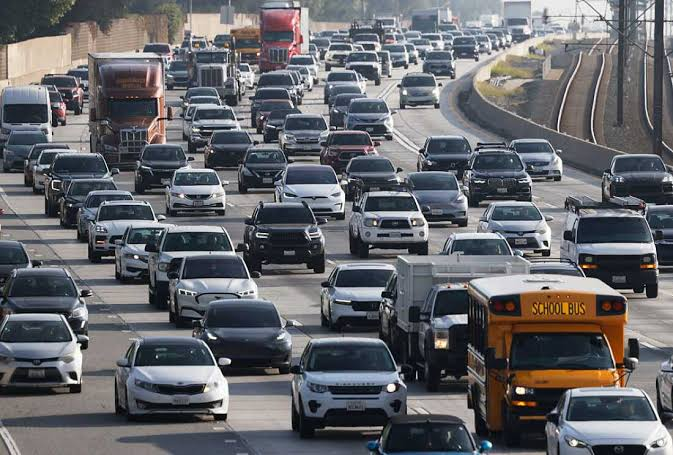

In [ ]:

# Upload traffic image from your computer

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

print("Image uploaded:", image_path)

# Read image using OpenCV
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Unable to read uploaded image")

print("Image dimensions:", image.shape)

# Display original image
display(Image(filename=image_path))


Image Height: 455
Image Width: 673
Number of Channels: 3
Image preprocessing completed!


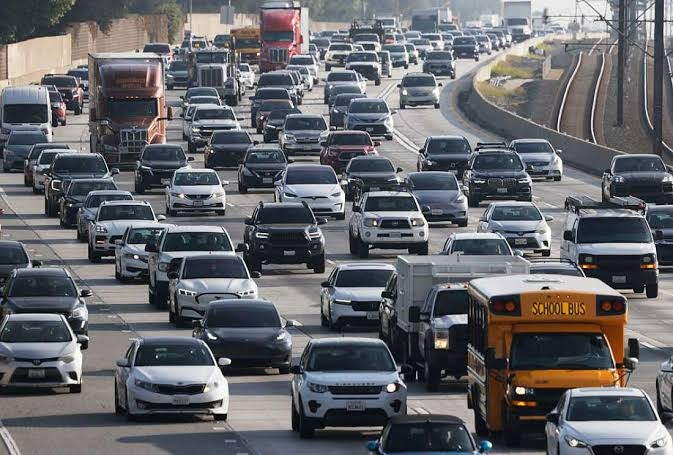

In [ ]:

# Check image properties

height, width, channels = image.shape

print("Image Height:", height)
print("Image Width:", width)
print("Number of Channels:", channels)

# Convert BGR to RGB
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Image preprocessing completed!")

display(Image(data=cv2.imencode(
    ".jpg",
    cv2.cvtColor(rgb_image, cv2.COLOR_RGB2BGR)
)[1].tobytes()))


In [ ]:

# Record starting time
start_time = time.time()

# Perform YOLOv8 inference
results = model.predict(
    source=image,
    conf=0.25,
    device=device,
    verbose=False
)

# Calculate inference time
end_time = time.time()

inference_time = end_time - start_time

print("Object detection completed!")
print("Inference Time:", round(inference_time, 4), "seconds")


Object detection completed!
Inference Time: 0.0663 seconds


VISIONPORT DETECTION OUTPUT


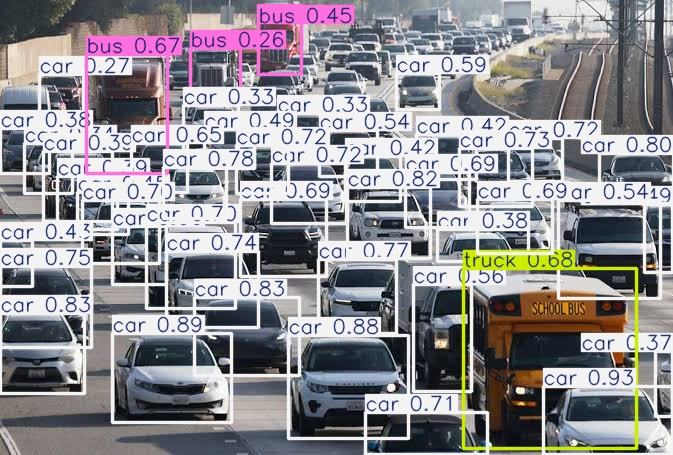

In [ ]:

# Generate annotated image with bounding boxes

annotated_image = results[0].plot()

# Convert BGR to RGB for notebook display
annotated_rgb = cv2.cvtColor(
    annotated_image,
    cv2.COLOR_BGR2RGB
)

print("VISIONPORT DETECTION OUTPUT")

display(Image(data=cv2.imencode(
    ".jpg",
    annotated_image
)[1].tobytes()))


In [ ]:

# Extract detection information

boxes = results[0].boxes

print("========== DETECTION REPORT ==========")

if boxes is not None and len(boxes) > 0:

    for i, box in enumerate(boxes):

        class_id = int(box.cls[0])

        class_name = model.names[class_id]

        confidence = float(box.conf[0])

        print(
            f"Object {i+1}: {class_name} | "
            f"Confidence: {confidence:.2%}"
        )

    print("\nTotal Objects Detected:", len(boxes))

else:
    print("No objects detected.")

print("Inference Time:", round(inference_time, 4), "seconds")


========== DETECTION REPORT ==========
Object 1: car | Confidence: 93.36%
Object 2: car | Confidence: 89.29%
Object 3: car | Confidence: 88.24%
Object 4: car | Confidence: 82.73%
Object 5: car | Confidence: 82.73%
Object 6: car | Confidence: 81.65%
Object 7: car | Confidence: 80.34%
Object 8: car | Confidence: 77.94%
Object 9: car | Confidence: 77.01%
Object 10: car | Confidence: 75.41%
Object 11: car | Confidence: 74.33%
Object 12: car | Confidence: 72.66%
Object 13: car | Confidence: 72.00%
Object 14: car | Confidence: 71.97%
Object 15: car | Confidence: 71.68%
Object 16: car | Confidence: 71.17%
Object 17: car | Confidence: 69.67%
Object 18: car | Confidence: 69.66%
Object 19: car | Confidence: 69.30%
Object 20: car | Confidence: 68.98%
Object 21: car | Confidence: 68.86%
Object 22: truck | Confidence: 68.09%
Object 23: bus | Confidence: 67.22%
Object 24: car | Confidence: 66.45%
Object 25: car | Confidence: 64.66%
Object 26: car | Confidence: 59.43%
Object 27: car | Confidence: 55.

In [ ]:

from fastapi import FastAPI, File, UploadFile, HTTPException
from fastapi.responses import StreamingResponse
from fastapi.middleware.cors import CORSMiddleware

# Initialize FastAPI
app = FastAPI(title="VisionPort Traffic Detection API")

# Enable frontend communication
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_methods=["*"],
    allow_headers=["*"]
)

# Home endpoint
@app.get("/")
def home():
    return {
        "project": "VisionPort",
        "status": "Active",
        "model": "YOLOv8 Nano"
    }


# Traffic detection endpoint
@app.post("/detect/")
async def detect_objects(file: UploadFile = File(...)):

    # Validate file
    if not file.content_type or not file.content_type.startswith("image/"):
        raise HTTPException(
            status_code=400,
            detail="Upload a valid image"
        )

    # Read uploaded image
    contents = await file.read()

    if not contents:
        raise HTTPException(
            status_code=400,
            detail="Empty image"
        )

    # Convert bytes into NumPy array
    nparr = np.frombuffer(contents, np.uint8)

    # Decode image
    img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

    if img is None:
        raise HTTPException(
            status_code=400,
            detail="Invalid image format"
        )

    # Run inference
    start = time.time()

    detection_results = model.predict(
        source=img,
        conf=0.25,
        device=device,
        verbose=False
    )

    processing_time = time.time() - start

    # Draw bounding boxes
    output = detection_results[0].plot()

    # Encode processed image
    success, encoded_img = cv2.imencode(".jpg", output)

    if not success:
        raise HTTPException(
            status_code=500,
            detail="Image encoding failed"
        )

    # Return processed image
    return StreamingResponse(
        io.BytesIO(encoded_img.tobytes()),
        media_type="image/jpeg",
        headers={
            "X-Processing-Time": str(round(processing_time, 4))
        }
    )

print("VisionPort FastAPI backend created!")


VisionPort FastAPI backend created!


In [ ]:

from fastapi.testclient import TestClient

# Create API test client
client = TestClient(app)

# Test home endpoint
response = client.get("/")

print("API STATUS:", response.status_code)
print("API RESPONSE:", response.json())


API STATUS: 200
API RESPONSE: {'project': 'VisionPort', 'status': 'Active', 'model': 'YOLOv8 Nano'}


Detection API Status: 200
Detection successful!
Processing Time: 0.0201 seconds


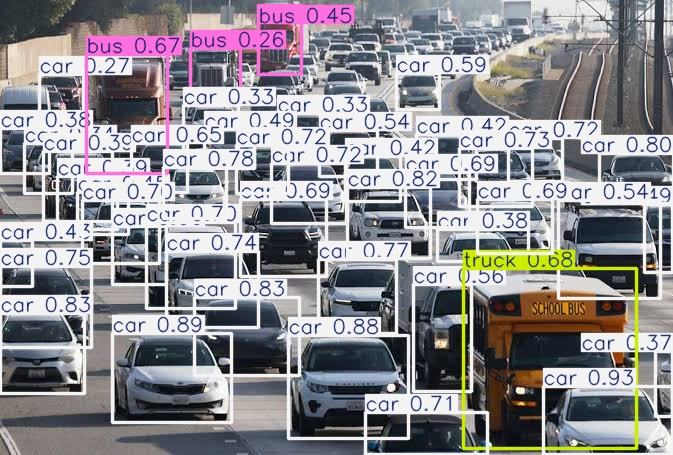

In [ ]:

# Open the uploaded image
with open(image_path, "rb") as image_file:

    response = client.post(
        "/detect/",
        files={
            "file": (
                "traffic.jpg",
                image_file,
                "image/jpeg"
            )
        }
    )

print("Detection API Status:", response.status_code)

if response.status_code == 200:

    print("Detection successful!")

    print(
        "Processing Time:",
        response.headers.get("X-Processing-Time"),
        "seconds"
    )

    # Display API returned image
    display(Image(data=response.content))

else:
    print("API Error:", response.text)


In [ ]:
cv2.imwrite("detected_output.jpg", annotated_image)

files.download("detected_output.jpg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>